In [1]:
%pip -q install opencv-contrib-python-headless requests pandas matplotlib
import os, time, requests, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from collections import defaultdict
print("OpenCV version:", cv2.__version__)
if not hasattr(cv2, "SIFT_create"):
    raise RuntimeError("SIFT is unavailable. Restart the runtime after installing opencv-contrib-python-headless.")
sift = cv2.SIFT_create(nfeatures=2500)
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)
BASE_DIR = Path("/content/landmark_database") if Path("/content").exists() else Path("landmark_database")
LANDMARKS = {
    "Eiffel_Tower": "Eiffel Tower Paris",
    "Taj_Mahal": "Taj Mahal Agra",
    "Great_Wall_of_China": "Great Wall of China",
    "Statue_of_Liberty": "Statue of Liberty New York",
    "Colosseum": "Colosseum Rome"
}
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
BASE_DIR.mkdir(parents=True, exist_ok=True)
LOWE_RATIO = 0.75
MIN_GOOD_MATCHES = 10
MIN_MATCH_MARGIN = 1.20
MIN_INLIERS = 8
MIN_INLIER_RATIO = 0.25
RANSAC_REPROJ_THRESHOLD = 5.0
print("Database:", BASE_DIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 9.9 MB/s eta 0:00:00
OpenCV version: 5.0.0
Database: /content/landmark_database


## Task 1 — Landmark Image Database

In [2]:

def task1_download_images(search_term, destination, target=4):
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    current = [p for p in destination.iterdir() if p.suffix.lower() in IMAGE_EXTS]
    if len(current) >= target:
        return len(current)
    api = "https://commons.wikimedia.org/w/api.php"
    headers = {"User-Agent": "SIFT-Landmark-Recognition-Lab/1.0 (educational use)"}
    params = {
        "action": "query", "format": "json", "generator": "search",
        "gsrsearch": f"filetype:bitmap {search_term}", "gsrnamespace": 6,
        "gsrlimit": 35, "prop": "imageinfo", "iiprop": "url", "iiurlwidth": 1200
    }
    try:
        response = requests.get(api, params=params, headers=headers, timeout=30)
        response.raise_for_status()
        pages = response.json().get("query", {}).get("pages", {})
        count = len(current)
        for item in sorted(pages.values(), key=lambda x: x.get("title", "")):
            if count >= target:
                break
            info = (item.get("imageinfo") or [{}])[0]
            url = info.get("thumburl") or info.get("url")
            if not url:
                continue
            try:
                r = requests.get(url, headers=headers, timeout=30)
                r.raise_for_status()
                arr = np.frombuffer(r.content, np.uint8)
                image = cv2.imdecode(arr, cv2.IMREAD_COLOR)
                if image is None or min(image.shape[:2]) < 180:
                    continue
                filename = destination / f"reference_{count+1:02d}.jpg"
                if cv2.imwrite(str(filename), image):
                    count += 1
            except Exception as e:
                print("Skipped one image:", str(e)[:120])
        return count
    except Exception as e:
        print(f"Automatic download failed for {search_term}: {e}")
        return len([p for p in destination.iterdir() if p.suffix.lower() in IMAGE_EXTS])

task1_summary = []
for landmark, search_term in LANDMARKS.items():
    folder = BASE_DIR / landmark
    folder.mkdir(parents=True, exist_ok=True)
    number = task1_download_images(search_term, folder, target=4)
    task1_summary.append({"Landmark": landmark, "Images available": number, "Folder": str(folder)})
display(pd.DataFrame(task1_summary))
print("\nFolder structure:")
for landmark in LANDMARKS:
    folder = BASE_DIR / landmark
    print(f"{landmark}/")
    for p in sorted(folder.iterdir()):
        if p.suffix.lower() in IMAGE_EXTS:
            print("   ", p.name)
print("\nRequirement: use multiple reference images per landmark with different angles/distances. If any folder is empty or has too few images, add images manually before Task 2.")

Skipped one image: 429 Client Error: Too Many Requests (015d12c) for url: https://upload.wikimedia.org/wikipedia/commons/1/16/Colosseum_Rom


,Landmark,Images available,Folder
0,Eiffel_Tower,4,/content/landmark_database/Eiffel_Tower
1,Taj_Mahal,4,/content/landmark_database/Taj_Mahal
2,Great_Wall_of_China,4,/content/landmark_database/Great_Wall_of_China
3,Statue_of_Liberty,4,/content/landmark_database/Statue_of_Liberty
4,Colosseum,4,/content/landmark_database/Colosseum



Folder structure:
Eiffel_Tower/
    reference_01.jpg
    reference_02.jpg
    reference_03.jpg
    reference_04.jpg
Taj_Mahal/
    reference_01.jpg
    reference_02.jpg
    reference_03.jpg
    reference_04.jpg
Great_Wall_of_China/
    reference_01.jpg
    reference_02.jpg
    reference_03.jpg
    reference_04.jpg
Statue_of_Liberty/
    reference_01.jpg
    reference_02.jpg
    reference_03.jpg
    reference_04.jpg
Colosseum/
    reference_01.jpg
    reference_02.jpg
    reference_03.jpg
    reference_04.jpg

Requirement: use multiple reference images per landmark with different angles/distances. If any folder is empty or has too few images, add images manually before Task 2.


## Task 2 — SIFT Feature Extraction

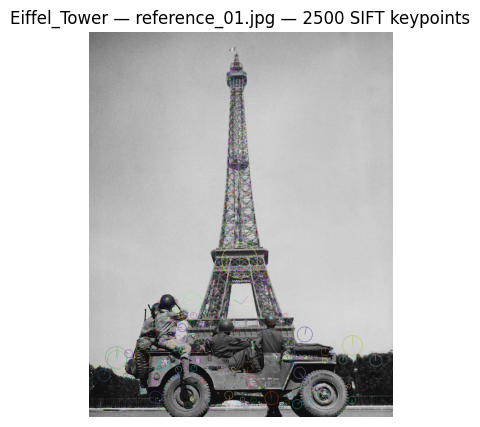

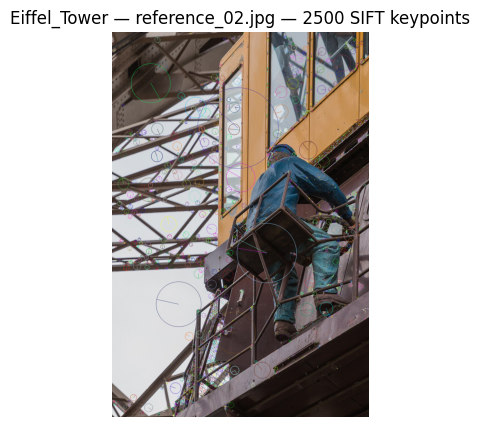

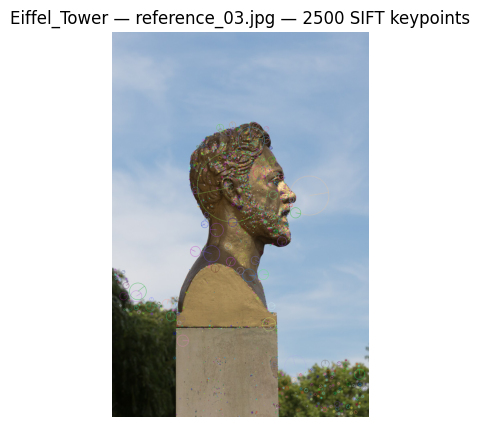

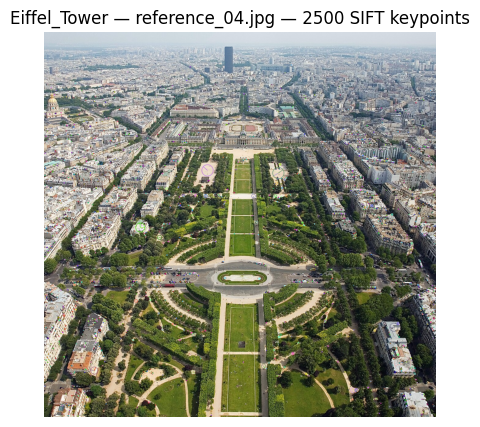

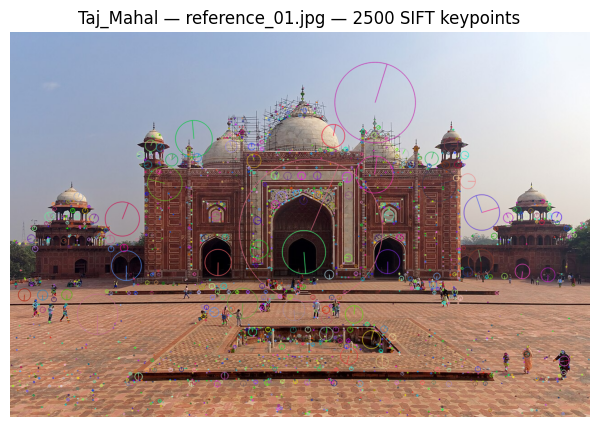

...

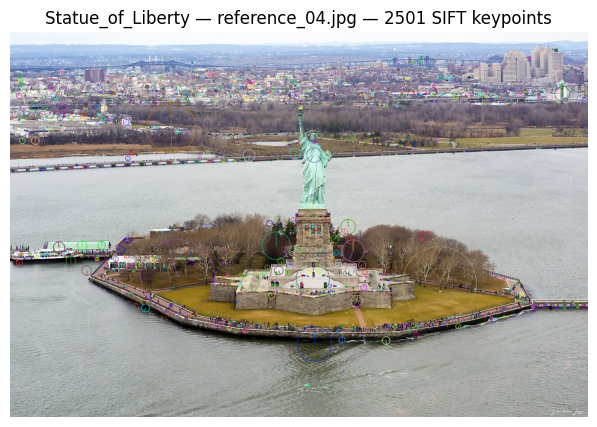

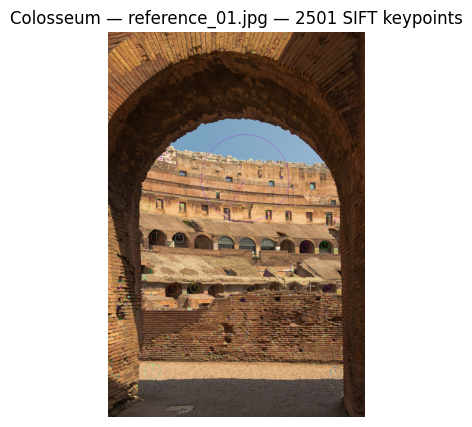

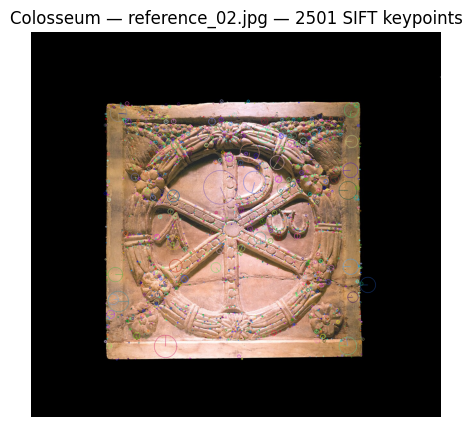

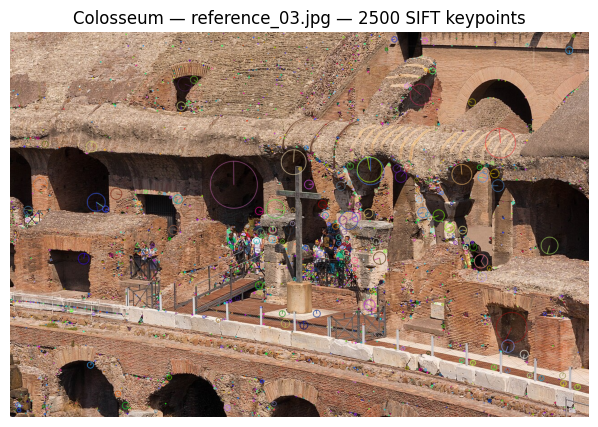

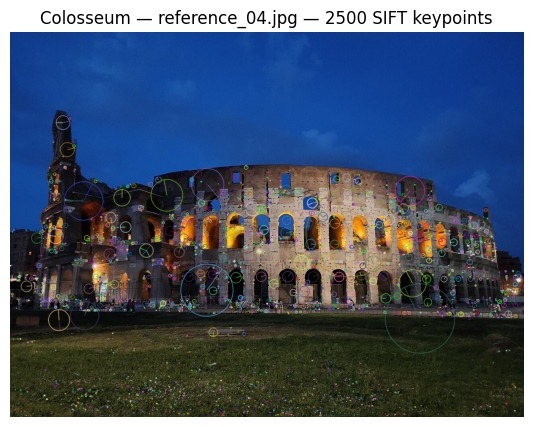

,Landmark,Image,Keypoints,Descriptors available
0,Eiffel_Tower,reference_01.jpg,2500,True
1,Eiffel_Tower,reference_02.jpg,2500,True
2,Eiffel_Tower,reference_03.jpg,2500,True
3,Eiffel_Tower,reference_04.jpg,2500,True
4,Taj_Mahal,reference_01.jpg,2500,True
5,Taj_Mahal,reference_02.jpg,2500,True
6,Taj_Mahal,reference_03.jpg,2500,True
7,Taj_Mahal,reference_04.jpg,2500,True
8,Great_Wall_of_China,reference_01.jpg,2500,True
9,Great_Wall_of_China,reference_02.jpg,2501,True


Reference images indexed: 20


In [3]:

def task2_read_color(path):
    return cv2.imread(str(path), cv2.IMREAD_COLOR)

def task2_extract_sift(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    return sift.detectAndCompute(gray, None)

database_images = []
reference_records = []
task2_rows = []
for landmark in LANDMARKS:
    folder = BASE_DIR / landmark
    files = sorted([p for p in folder.iterdir() if p.suffix.lower() in IMAGE_EXTS]) if folder.exists() else []
    for path in files:
        image = task2_read_color(path)
        if image is None:
            print("Could not read:", path)
            continue
        keypoints, descriptors = task2_extract_sift(image)
        task2_rows.append({"Landmark": landmark, "Image": path.name,
                           "Keypoints": len(keypoints), "Descriptors available": descriptors is not None})
        database_images.append({"label": landmark, "path": str(path), "image": image})
        if descriptors is not None and len(keypoints) >= 4:
            reference_records.append({"label": landmark, "path": str(path), "image": image,
                                      "keypoints": keypoints, "descriptors": descriptors})
        drawn = cv2.drawKeypoints(image, keypoints, None,
                                  flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        plt.figure(figsize=(8, 5))
        plt.imshow(cv2.cvtColor(drawn, cv2.COLOR_BGR2RGB))
        plt.title(f"{landmark} — {path.name} — {len(keypoints)} SIFT keypoints")
        plt.axis("off")
        plt.show()
display(pd.DataFrame(task2_rows))
print("Reference images indexed:", len(reference_records))
if not reference_records:
    raise RuntimeError("No usable reference descriptors. Add clear images to the landmark folders, then rerun Task 2.")

## Task 3 — Query Image Processing

Saving taj mahal.jpg to taj mahal.jpg


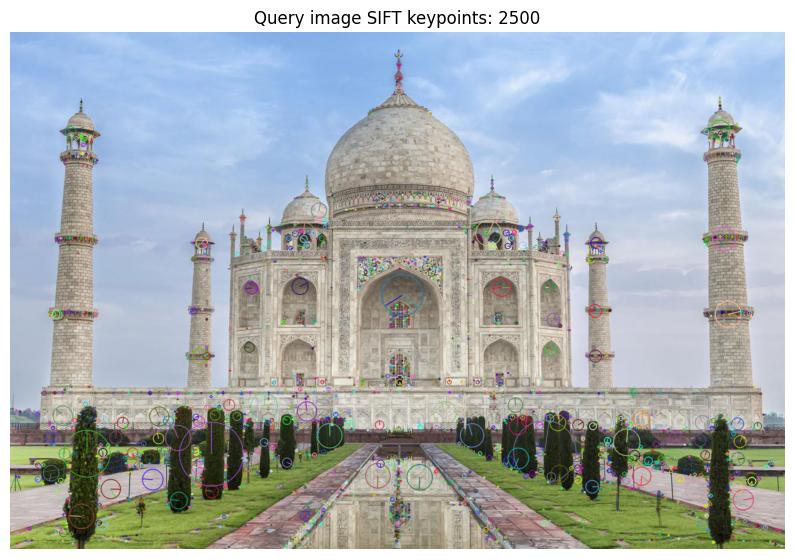

Query keypoints: 2500
Descriptor shape: (2500, 128)


In [4]:

QUERY_PATH = None
try:
    from google.colab import files
    uploaded_query = files.upload()
    if uploaded_query:
        QUERY_PATH = next(iter(uploaded_query.keys()))
except Exception:
    QUERY_PATH = input("Enter the query image path: ").strip() or None

query_image = None
query_keypoints = None
query_descriptors = None
if not QUERY_PATH:
    print("No query image selected. Set QUERY_PATH to a valid image path and rerun Task 3.")
else:
    query_image = cv2.imread(str(QUERY_PATH), cv2.IMREAD_COLOR)
    if query_image is None:
        raise ValueError(f"Could not load query image: {QUERY_PATH}")
    query_gray = cv2.cvtColor(query_image, cv2.COLOR_BGR2GRAY)
    query_keypoints, query_descriptors = sift.detectAndCompute(query_gray, None)
    query_display = cv2.drawKeypoints(query_image, query_keypoints, None,
                                      flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.figure(figsize=(10, 7))
    plt.imshow(cv2.cvtColor(query_display, cv2.COLOR_BGR2RGB))
    plt.title(f"Query image SIFT keypoints: {len(query_keypoints)}")
    plt.axis("off")
    plt.show()
    print("Query keypoints:", len(query_keypoints))
    print("Descriptor shape:", None if query_descriptors is None else query_descriptors.shape)

## Task 4 — Feature Matching and Landmark Recognition

In [5]:

def task4_match_record(q_descriptors, record):
    if q_descriptors is None or record["descriptors"] is None or len(q_descriptors) < 2:
        return []
    pairs = bf.knnMatch(record["descriptors"], q_descriptors, k=2)
    return [m for pair in pairs if len(pair) == 2 for m, n in [pair] if m.distance < LOWE_RATIO * n.distance]

def task4_candidate(good, record, qkp, qshape):
    result = {"label": record["label"], "path": record["path"], "good_matches": len(good),
              "inliers": 0, "inlier_ratio": 0.0, "homography": None, "polygon": None,
              "geometric_ok": False, "good": good, "record": record}
    if len(good) < 4:
        return result
    src = np.float32([record["keypoints"][m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([qkp[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_REPROJ_THRESHOLD)
    if H is None or mask is None:
        return result
    result["homography"] = H
    result["inliers"] = int(mask.ravel().sum())
    result["inlier_ratio"] = result["inliers"] / max(len(good), 1)
    h, w = record["image"].shape[:2]
    corners = np.float32([[0, 0], [w-1, 0], [w-1, h-1], [0, h-1]]).reshape(-1, 1, 2)
    try:
        projected = cv2.perspectiveTransform(corners, H).reshape(4, 2)
        qh, qw = qshape[:2]
        finite = np.isfinite(projected).all()
        extent_ok = (projected[:, 0].min() > -qw and projected[:, 0].max() < 2*qw and
                     projected[:, 1].min() > -qh and projected[:, 1].max() < 2*qh)
        area = abs(cv2.contourArea(projected.astype(np.float32)))
        area_ok = 100 <= area <= 4 * qh * qw
        if finite and extent_ok and area_ok:
            result["polygon"] = projected.astype(np.int32)
            result["geometric_ok"] = (result["inliers"] >= MIN_INLIERS and
                                      result["inlier_ratio"] >= MIN_INLIER_RATIO)
    except Exception:
        pass
    return result

task4_result = None
if query_image is None or query_keypoints is None:
    print("Run Task 3 successfully first.")
else:
    start_time = time.perf_counter()
    candidate_list = []
    for record in reference_records:
        good = task4_match_record(query_descriptors, record)
        candidate_list.append(task4_candidate(good, record, query_keypoints, query_image.shape))
    best_by_label = {}
    for candidate in candidate_list:
        label = candidate["label"]
        score = (candidate["inliers"], candidate["good_matches"], candidate["inlier_ratio"])
        previous = best_by_label.get(label)
        if previous is None or score > (previous["inliers"], previous["good_matches"], previous["inlier_ratio"]):
            best_by_label[label] = candidate
    ranked_candidates = sorted(best_by_label.values(),
                               key=lambda x: (x["inliers"], x["good_matches"], x["inlier_ratio"]),
                               reverse=True)
    best_candidate = ranked_candidates[0] if ranked_candidates else None
    second_candidate = ranked_candidates[1] if len(ranked_candidates) > 1 else None
    margin_ok = (best_candidate is not None and
                 (second_candidate is None or best_candidate["good_matches"] >=
                  MIN_MATCH_MARGIN * max(second_candidate["good_matches"], 1)))
    recognized = bool(best_candidate and best_candidate["good_matches"] >= MIN_GOOD_MATCHES
                      and margin_ok and best_candidate["geometric_ok"])
    elapsed = time.perf_counter() - start_time
    task4_result = {"predicted": best_candidate["label"] if recognized else "Unknown / Rejected",
                    "recognized": recognized, "keypoints": len(query_keypoints),
                    "good_matches": best_candidate["good_matches"] if best_candidate else 0,
                    "inliers": best_candidate["inliers"] if best_candidate else 0,
                    "processing_time": elapsed, "best": best_candidate, "ranked": ranked_candidates}
    print("Ranked candidates:")
    display(pd.DataFrame([{"Landmark": x["label"], "Reliable matches": x["good_matches"],
                           "RANSAC inliers": x["inliers"], "Inlier ratio": round(x["inlier_ratio"], 3),
                           "Geometric verification": x["geometric_ok"]} for x in ranked_candidates]))
    print("Predicted landmark:", task4_result["predicted"])
    print("Reliable matches:", task4_result["good_matches"])
    print("Decision:", "RECOGNIZED" if recognized else "REJECTED")
    print("Processing time (s):", round(elapsed, 4))

Ranked candidates:


,Landmark,Reliable matches,RANSAC inliers,Inlier ratio,Geometric verification
0,Eiffel_Tower,52,20,0.385,False
1,Taj_Mahal,44,18,0.409,False
2,Colosseum,40,12,0.300,False
3,Statue_of_Liberty,20,8,0.400,False
4,Great_Wall_of_China,13,6,0.462,False


Predicted landmark: Unknown / Rejected
Reliable matches: 52
Decision: REJECTED
Processing time (s): 4.9908


## Task 5 — Landmark Localization

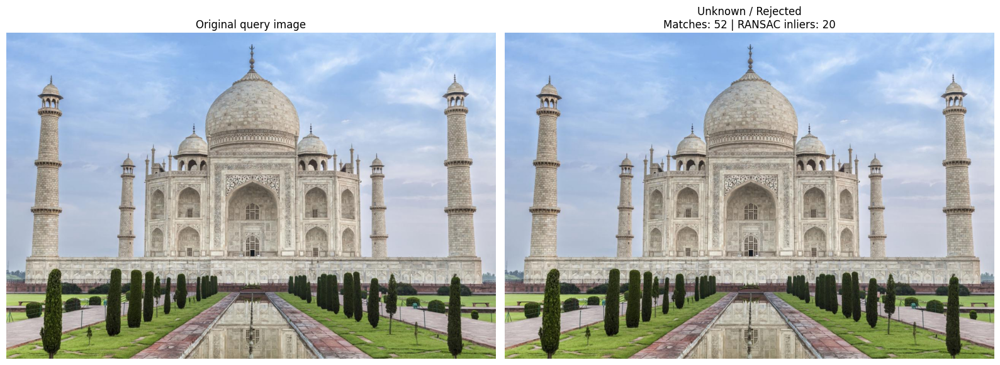

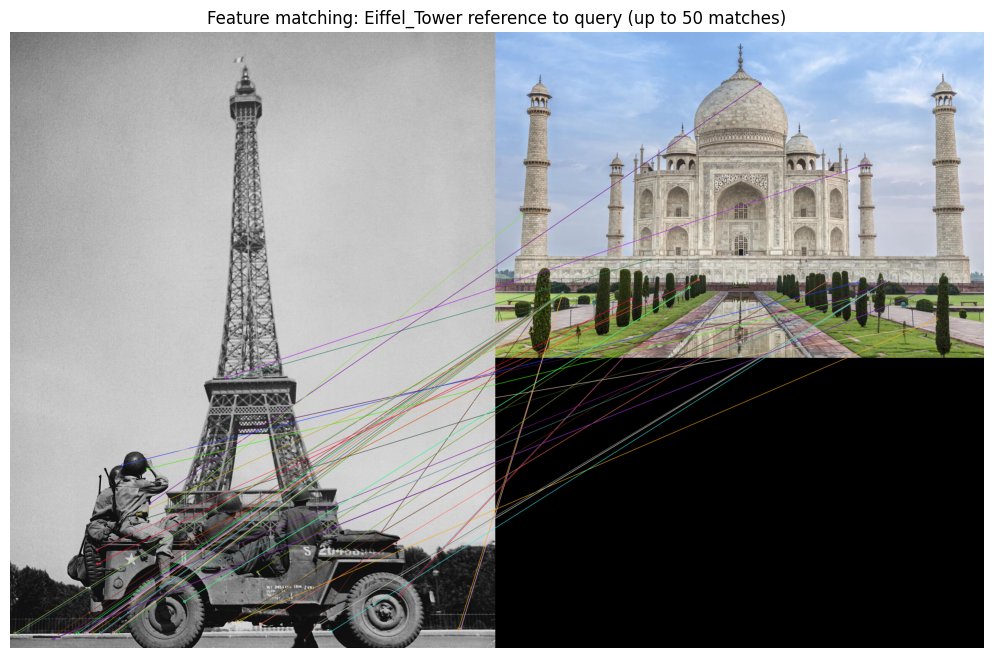

Localization unreliable: insufficient matches/inliers or invalid homography. Polygon not drawn.
Reliable matches: 52
RANSAC inliers: 20
Inlier ratio: 0.385
Geometric verification: failed
Recognition decision: REJECTED


In [6]:

if query_image is None or task4_result is None or task4_result["best"] is None:
    print("Run Tasks 3 and 4 first and ensure at least one candidate exists.")
else:
    best = task4_result["best"]
    localized_image = query_image.copy()
    if task4_result["recognized"] and best["geometric_ok"] and best["polygon"] is not None:
        cv2.polylines(localized_image, [best["polygon"].reshape(-1, 1, 2)], True, (0, 255, 0), 4)
        localization_message = "Landmark localized successfully."
    else:
        localization_message = "Localization unreliable: insufficient matches/inliers or invalid homography. Polygon not drawn."
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(cv2.cvtColor(query_image, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original query image")
    axes[0].axis("off")
    axes[1].imshow(cv2.cvtColor(localized_image, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f'{task4_result["predicted"]}\nMatches: {best["good_matches"]} | RANSAC inliers: {best["inliers"]}')
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()
    if best["good"]:
        match_visual = cv2.drawMatches(best["record"]["image"], best["record"]["keypoints"],
                                       query_image, query_keypoints, best["good"][:50], None,
                                       flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        plt.figure(figsize=(18, 8))
        plt.imshow(cv2.cvtColor(match_visual, cv2.COLOR_BGR2RGB))
        plt.title(f'Feature matching: {best["label"]} reference to query (up to 50 matches)')
        plt.axis("off")
        plt.show()
    print(localization_message)
    print("Reliable matches:", best["good_matches"])
    print("RANSAC inliers:", best["inliers"])
    print("Inlier ratio:", round(best["inlier_ratio"], 3))
    print("Geometric verification:", "passed" if best["geometric_ok"] else "failed")
    print("Recognition decision:", "RECOGNIZED" if task4_result["recognized"] else "REJECTED")

## Task 6 — Performance Evaluation

In [8]:

def task6_rotate(image, angle=25):
    h, w = image.shape[:2]
    matrix = cv2.getRotationMatrix2D((w/2, h/2), angle, 1.0)
    return cv2.warpAffine(image, matrix, (w, h), borderMode=cv2.BORDER_REFLECT)

def task6_resize(image, scale=0.65):
    h, w = image.shape[:2]
    return cv2.resize(image, (max(1, int(w*scale)), max(1, int(h*scale))), interpolation=cv2.INTER_AREA)

def task6_dark(image, factor=0.45):
    return np.clip(image.astype(np.float32) * factor, 0, 255).astype(np.uint8)

def task6_evaluate_one(test_name, image):
    start = time.perf_counter()
    qkp, qdesc = sift.detectAndCompute(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), None)
    candidates = []
    for record in reference_records:
        good = task4_match_record(qdesc, record)
        candidates.append(task4_candidate(good, record, qkp, image.shape))
    best_by_label = {}
    for c in candidates:
        old = best_by_label.get(c["label"])
        if old is None or (c["inliers"], c["good_matches"], c["inlier_ratio"]) > (old["inliers"], old["good_matches"], old["inlier_ratio"]):
            best_by_label[c["label"]] = c
    ranked = sorted(best_by_label.values(), key=lambda x: (x["inliers"], x["good_matches"], x["inlier_ratio"]), reverse=True)
    best = ranked[0] if ranked else None
    runner = ranked[1] if len(ranked) > 1 else None
    margin = bool(best and (runner is None or best["good_matches"] >= MIN_MATCH_MARGIN * max(runner["good_matches"], 1)))
    ok = bool(best and best["good_matches"] >= MIN_GOOD_MATCHES and margin and best["geometric_ok"])
    elapsed = time.perf_counter() - start
    return {"Test": test_name, "Predicted landmark": best["label"] if ok else "Unknown / Rejected",
            "Query keypoints": len(qkp), "Reliable matches": best["good_matches"] if best else 0,
            "RANSAC inliers": best["inliers"] if best else 0,
            "Recognition decision": "Recognized" if ok else "Rejected",
            "Processing time (s)": round(elapsed, 4)}

first_record = reference_records[0] if reference_records else None
if first_record is None:
    raise RuntimeError("No indexed reference images. Complete Tasks 1 and 2 first.")
evaluation_tests = [
    ("Original landmark image", first_record["image"]),
    ("Rotated landmark image (+25 degrees)", task6_rotate(first_record["image"], 25)),
    ("Resized landmark image (65%)", task6_resize(first_record["image"], 0.65)),
    ("Reduced brightness (45%)", task6_dark(first_record["image"], 0.45))
]
same_label_others = [r for r in reference_records if r["label"] == first_record["label"] and r["path"] != first_record["path"]]
if same_label_others:
    evaluation_tests.append(("Different reference viewpoint/photo", same_label_others[0]["image"]))
else:
    print("VIEWPOINT TEST NOTE: Add a second independent photo for", first_record["label"],
          "to its folder and rerun Task 2 and Task 6 for a real different-viewpoint test.")

unknown_path = None
try:
    from google.colab import files
    print("Optional but required for full evaluation: upload a photo of a landmark NOT in the five-landmark database.")
    unknown_upload = files.upload()
    if unknown_upload:
        unknown_path = next(iter(unknown_upload.keys()))
except Exception:
    entered = input("Optional unknown landmark image path (press Enter to skip): ").strip()
    unknown_path = entered or None
if unknown_path:
    unknown_image = cv2.imread(str(unknown_path), cv2.IMREAD_COLOR)
    if unknown_image is not None:
        evaluation_tests.append(("Unknown landmark (not in database)", unknown_image))
    else:
        print("Could not read unknown image:", unknown_path)

evaluation_rows = [task6_evaluate_one(name, image) for name, image in evaluation_tests]
evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df)
evaluation_df.to_csv("landmark_evaluation_results.csv", index=False)
print("Saved experimental results to landmark_evaluation_results.csv")
try:
    from google.colab import files
    files.download("landmark_evaluation_results.csv")
except Exception:
    print("CSV is saved in the current working directory.")

print("\nDISCUSSION / LIMITATIONS")
print("- SIFT is designed to tolerate moderate scale and rotation changes.")
print("- Illumination changes may still reduce descriptor matches, especially in severe shadows or overexposure.")
print("- Different viewpoints may show different surfaces; multiple reference views improve recognition.")
print("- RANSAC homography works best when matched image regions are approximately planar.")
print("- Unknown rejection uses match count, separation from the runner-up, and geometric inlier checks.")
print("- Repeated patterns, blur, occlusion, poor references, or extreme viewpoint changes can cause false rejection or false recognition.")
print("- For a valid report, record actual results from this table and use an independent unknown-landmark photograph.")

Optional but required for full evaluation: upload a photo of a landmark NOT in the five-landmark database.


Saving effil tower.jpg to effil tower.jpg


,Test,Predicted landmark,Query keypoints,Reliable matches,RANSAC inliers,Recognition decision,Processing time (s)
0,Original landmark image,Eiffel_Tower,2500,2500,2500,Recognized,5.5028
1,Rotated landmark image (+25 degrees),Eiffel_Tower,2500,1709,1644,Recognized,5.1208
2,Resized landmark image (65%),Eiffel_Tower,2500,1192,1144,Recognized,4.2644
3,Reduced brightness (45%),Eiffel_Tower,2500,2400,2396,Recognized,6.0758
4,Different reference viewpoint/photo,Eiffel_Tower,2500,2500,2500,Recognized,4.7003
5,Unknown landmark (not in database),Unknown / Rejected,2501,38,11,Rejected,4.1141


Saved experimental results to landmark_evaluation_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DISCUSSION / LIMITATIONS
- SIFT is designed to tolerate moderate scale and rotation changes.
- Illumination changes may still reduce descriptor matches, especially in severe shadows or overexposure.
- Different viewpoints may show different surfaces; multiple reference views improve recognition.
- RANSAC homography works best when matched image regions are approximately planar.
- Unknown rejection uses match count, separation from the runner-up, and geometric inlier checks.
- Repeated patterns, blur, occlusion, poor references, or extreme viewpoint changes can cause false rejection or false recognition.
- For a valid report, record actual results from this table and use an independent unknown-landmark photograph.
